In [125]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from scipy.stats import pearsonr

#load the csv file
df = pd.read_csv("dry straight hair data/Extension_Dry_2mmmin_S.csv")
print(df)

       Record  Strain (%)  Stress (MPa)
0           1         0.0           0.1
1           1         0.0          -0.1
2           1         0.0           0.0
3           1         0.0           0.1
4           1         0.0           0.0
...       ...         ...           ...
20288      25         4.0           3.2
20289      25         4.0           3.3
20290      25         4.0           3.2
20291      25         4.0           3.7
20292      25         4.0           4.1

[20293 rows x 3 columns]


In [126]:
#Convert columns to numbers
df["Strain (%)"] = pd.to_numeric(df["Strain (%)"], errors='coerce')
df["Stress (MPa)"] = pd.to_numeric(df["Stress (MPa)"], errors='coerce')
df = df.dropna(subset=["Strain (%)", "Stress (MPa)"])  # Drop rows with NaN values in these columns

#Sort by strain
df = df.sort_values("Strain (%)")

#Check the data
print(df.head())
print(df.info())

    Record  Strain (%)  Stress (MPa)
0        1         0.0           0.1
20       1         0.0           0.3
19       1         0.0           0.1
18       1         0.0           0.1
17       1         0.0           0.1
<class 'pandas.core.frame.DataFrame'>
Index: 20293 entries, 0 to 14608
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Record        20293 non-null  int64  
 1   Strain (%)    20293 non-null  float64
 2   Stress (MPa)  20293 non-null  float64
dtypes: float64(2), int64(1)
memory usage: 634.2 KB
None


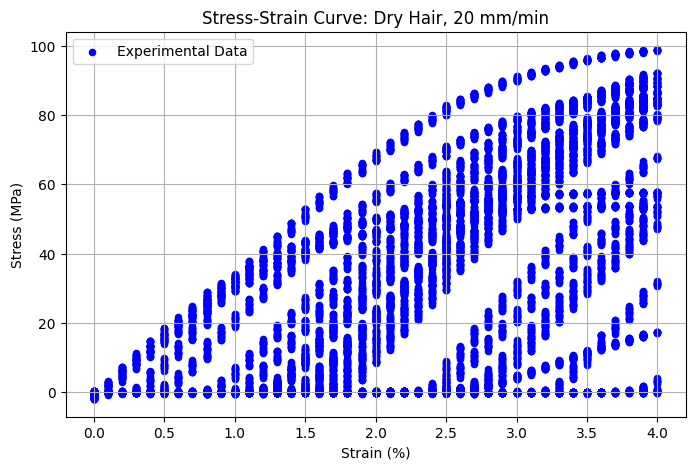

In [127]:
plt.figure(figsize=(8, 5)) #Raw stress-strain data
plt.scatter(df["Strain (%)"], df["Stress (MPa)"], s=20, label = "Experimental Data", color='blue')

plt.xlabel("Strain (%)")
plt.ylabel("Stress (MPa)")
plt.title("Stress-Strain Curve: Dry Hair, 20 mm/min")
plt.legend()
plt.grid(True)
plt.show()

In [128]:
mean_df = (df.groupby("Strain (%)")["Stress (MPa)"].agg(['mean', 'std']).reset_index())
print(mean_df)

    Strain (%)       mean        std
0          0.0  -0.116800   0.350542
1          0.1   0.115254   0.550406
2          0.2   0.431858   1.529547
3          0.3   0.765675   2.520360
4          0.4   1.225280   3.556654
5          0.5   1.608864   4.508679
6          0.6   2.107919   5.529312
7          0.7   2.858209   6.933278
8          0.8   3.613810   8.412869
9          0.9   4.017460   9.371288
10         1.0   4.918143  10.755273
11         1.1   6.059193  12.187243
12         1.2   6.062471  12.541429
13         1.3   7.569507  14.091612
14         1.4   8.824622  15.068180
15         1.5  10.387555  16.240812
16         1.6  11.872889  17.010702
17         1.7  13.814516  17.820386
18         1.8  15.816847  19.108032
19         1.9  17.512357  19.425618
20         2.0  20.320136  20.833202
21         2.1  22.272331  21.945615
22         2.2  24.309607  22.947064
23         2.3  26.711702  24.290469
24         2.4  28.072374  25.268133
25         2.5  31.049421  26.422272
2

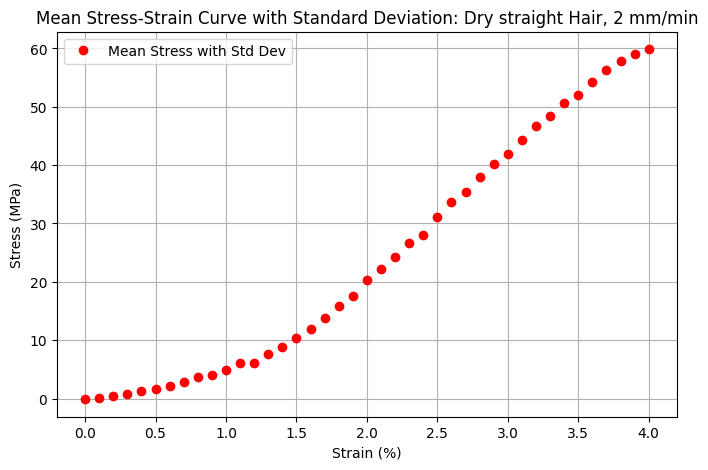

In [129]:
plt.figure(figsize=(8, 5)) 
plt.errorbar(mean_df["Strain (%)"], mean_df["mean"], fmt='o', label='Mean Stress with Std Dev', color='red', capsize=3)

plt.xlabel("Strain (%)")
plt.ylabel("Stress (MPa)")
plt.title("Mean Stress-Strain Curve with Standard Deviation: Dry straight Hair, 2 mm/min")
plt.legend()
plt.grid(True)
plt.show()

In [130]:
strain = mean_df["Strain (%)"].values
stress = mean_df["mean"].values

#Define the exponential model
def exponential(x, A, B):
    return A * (np.exp(B * x) - 1)

# 3. Set minimum number of points
# ==========================================

MIN_POINTS_TOE = 18
MIN_POINTS_ELASTIC = 16

# 4. Define possible breakpoints
# ==========================================

# Only search between these strain values
min_breakpoint = 0.01
max_breakpoint = 4.6

possible_breakpoints = np.linspace(min_breakpoint,max_breakpoint,100)

#5. Store results
# ==========================================

results = []


# 6. Test every possible breakpoint
# ==========================================
# loop through each possible breakpoint and fit the toe and elastic regions separately, then calculate the MSE for each fit.
for breakpoint in possible_breakpoints:

    # -----------------------------
    # Divide data
    # -----------------------------

    toe_mask = strain <= breakpoint
    elastic_mask = strain > breakpoint

    toe_strain = strain[toe_mask]
    toe_stress = stress[toe_mask]

    elastic_strain = strain[elastic_mask]
    elastic_stress = stress[elastic_mask]


    # -----------------------------
    # Minimum point requirement
    # -----------------------------

    if len(toe_strain) < MIN_POINTS_TOE:
        continue

    if len(elastic_strain) < MIN_POINTS_ELASTIC:
        continue


    # ==========================================
    # 7. Fit exponential to toe region
    # ==========================================

    try:

        popt_exp, _ = curve_fit(
            exponential,
            toe_strain,
            toe_stress,
            p0=[1, 1],
            maxfev=10000
        )

    except RuntimeError:

        continue


    A, B = popt_exp


    # Predicted toe stresses

    predicted_toe = exponential(
        toe_strain,
        A,
        B
    )


    # ==========================================
    # 8. Fit linear elastic region
    # ==========================================

    linear_coefficients = np.polyfit(
        elastic_strain,
        elastic_stress,
        1
    )

    E = linear_coefficients[0]
    C = linear_coefficients[1]


    # Predicted elastic stresses

    predicted_elastic = (
        E * elastic_strain + C
    )


    # ==========================================
    # 9. Calculate MSE
    # ==========================================

    toe_mse = np.mean(
        (toe_stress - predicted_toe) ** 2
    )

    elastic_mse = np.mean(
        (elastic_stress - predicted_elastic) ** 2
    )


    # ==========================================
    # 10. Combined MSE
    # ==========================================

    total_mse = toe_mse + elastic_mse #total MSE is the sum of the toe and elastic MSEs


    # ==========================================
    # 11. Store results
    # ==========================================

    results.append({
        "breakpoint": breakpoint,
        "toe_mse": toe_mse,
        "elastic_mse": elastic_mse,
        "total_mse": total_mse,
        "A": A,
        "B": B,
        "E": E,
        "C": C,
        "n_toe": len(toe_strain),
        "n_elastic": len(elastic_strain)
    })


#12. Convert results to DataFrame
# ==========================================

results_df = pd.DataFrame(results)


# ==========================================
# 13. Find best breakpoint
# ==========================================

best_index = results_df["total_mse"].idxmin()

best_result = results_df.loc[best_index]


print("\nBEST BREAKPOINT")
print("----------------------")

print(
    "Breakpoint strain:",
    best_result["breakpoint"]
)

print(
    "Toe MSE:",
    best_result["toe_mse"]
)

print(
    "Elastic MSE:",
    best_result["elastic_mse"]
)

print(
    "Total MSE:",
    best_result["total_mse"]
)

print(
    "Number of toe points:",
    int(best_result["n_toe"])
)

print(
    "Number of elastic points:",
    int(best_result["n_elastic"])
)

print("\nToe exponential parameters")

print(
    "A =",
    best_result["A"]
)

print(
    "B =",
    best_result["B"]
)

print("\nElastic linear parameters")

print(
    "E =",
    best_result["E"]
)

print(
    "C =",
    best_result["C"]
)



BEST BREAKPOINT
----------------------
Breakpoint strain: 1.910909090909091
Toe MSE: 0.04457232360893151
Elastic MSE: 0.6246635132677246
Total MSE: 0.6692358368766561
Number of toe points: 20
Number of elastic points: 21

Toe exponential parameters
A = 2.159772797002498
B = 1.1695845000188738

Elastic linear parameters
E = 20.68327408710649
C = -20.56231612747894


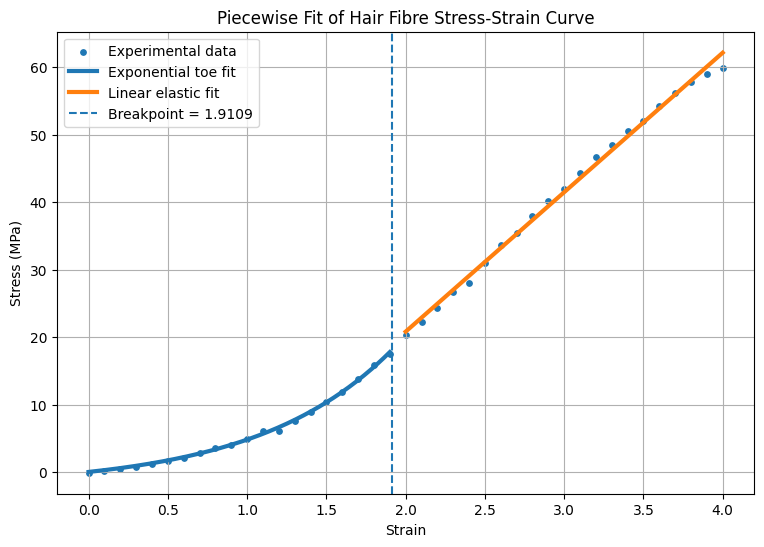

In [131]:
best_breakpoint = best_result["breakpoint"]

toe_mask = strain <= best_breakpoint
elastic_mask = strain > best_breakpoint

toe_strain = strain[toe_mask]
toe_stress = stress[toe_mask]

elastic_strain = strain[elastic_mask]
elastic_stress = stress[elastic_mask]


# Exponential fit

A = best_result["A"]
B = best_result["B"]

toe_x = np.linspace(
    toe_strain.min(),
    toe_strain.max(),
    200
)

toe_y = exponential(
    toe_x,
    A,
    B
)


# Linear fit

E = best_result["E"]
C = best_result["C"]

elastic_x = np.linspace(
    elastic_strain.min(),
    elastic_strain.max(),
    200
)

elastic_y = E * elastic_x + C


# Plot

plt.figure(figsize=(9, 6))

plt.scatter(
    strain,
    stress,
    s=15,
    label="Experimental data"
)

plt.plot(
    toe_x,
    toe_y,
    linewidth=3,
    label="Exponential toe fit"
)

plt.plot(
    elastic_x,
    elastic_y,
    linewidth=3,
    label="Linear elastic fit"
)

plt.axvline(
    best_breakpoint,
    linestyle="--",
    label=f"Breakpoint = {best_breakpoint:.4f}"
)

plt.xlabel("Strain")
plt.ylabel("Stress (MPa)")
plt.title("Piecewise Fit of Hair Fibre Stress-Strain Curve")

plt.legend()
plt.grid(True)

plt.show()

In [132]:
# Use the selected best breakpoint instead of the last loop value
breakpoint = best_breakpoint

toe_mask = strain <= breakpoint
elastic_mask = strain > breakpoint

toe_strain = strain[toe_mask]
toe_stress = stress[toe_mask]

elastic_strain = strain[elastic_mask]
elastic_stress = stress[elastic_mask]

# 2. Calculate predicted stress
# ------------------------------------------

def exponential(x, A, B):
    return A * (np.exp(B * x) - 1)

predicted_toe = exponential(toe_strain, A, B)
predicted_elastic = E * elastic_strain + C

# 3. Toe-region length
# ------------------------------------------

toe_length = breakpoint - np.min(strain)

# ------------------------------------------
# 4. Stress at transition
# ------------------------------------------

stress_transition_toe = exponential(breakpoint, A, B)
stress_transition_elastic = E * breakpoint + C

# Difference between the two models at the breakpoint
transition_gap = stress_transition_elastic - stress_transition_toe

# 5. Effective toe-region stiffness
# ------------------------------------------

# Derivative of A*(exp(B*strain) - 1)
toe_stiffness_transition = A * B * np.exp(B * breakpoint)

# ------------------------------------------
# 6. Elastic modulus
# ------------------------------------------

elastic_modulus = E

# 7. Correlation and R-squared
# ------------------------------------------

def calculate_metrics(observed, predicted):
    residuals = observed - predicted

    sse = np.sum(residuals ** 2)
    mse = np.mean(residuals ** 2)
    rmse = np.sqrt(mse)

    sst = np.sum((observed - np.mean(observed)) ** 2)

    r_squared = 1 - sse / sst if sst > 0 else np.nan

    # Pearson correlation is undefined for constant arrays
    if (
        len(observed) >= 2
        and np.std(observed) > 0
        and np.std(predicted) > 0
    ):
        r = pearsonr(observed, predicted).statistic
    else:
        r = np.nan

    return {
        "r": r,
        "R_squared": r_squared,
        "SSE": sse,
        "MSE": mse,
        "RMSE": rmse,
        "residuals": residuals
    }

toe_metrics = calculate_metrics(toe_stress, predicted_toe)
elastic_metrics = calculate_metrics(elastic_stress, predicted_elastic)

all_stress = np.concatenate([toe_stress, elastic_stress])
all_predicted = np.concatenate([predicted_toe, predicted_elastic])

overall_metrics = calculate_metrics(all_stress, all_predicted)

# ------------------------------------------
# 8. Print results
# ------------------------------------------

print("\n===== HAIR FIBRE ANALYSIS =====")

print(f"Breakpoint strain: {breakpoint:.6f}")
print(f"Toe-region length: {toe_length:.6f}")

print("\nStress at transition:")
print(f"Exponential fit: {stress_transition_toe:.6f}")
print(f"Linear fit:      {stress_transition_elastic:.6f}")
print(f"Transition gap:  {transition_gap:.6f}")

print("\nToe-region stiffness at transition:")
print(f"{toe_stiffness_transition:.6f} stress units per strain unit")

print("\nElastic modulus:")
print(f"{elastic_modulus:.6f} stress units per strain unit")

for name, metrics in [
    ("TOE REGION", toe_metrics),
    ("ELASTIC REGION", elastic_metrics),
    ("OVERALL", overall_metrics)
]:
    print(f"\n{name}")
    print(f"Pearson r: {metrics['r']:.5f}")
    print(f"R-squared: {metrics['R_squared']:.5f}")
    print(f"SSE:       {metrics['SSE']:.6f}")
    print(f"MSE:       {metrics['MSE']:.6f}")
    print(f"RMSE:      {metrics['RMSE']:.6f}")


===== HAIR FIBRE ANALYSIS =====
Breakpoint strain: 1.910909
Toe-region length: 1.910909

Stress at transition:
Exponential fit: 18.025892
Linear fit:      18.961540
Transition gap:  0.935648

Toe-region stiffness at transition:
23.608841 stress units per strain unit

Elastic modulus:
20.683274 stress units per strain unit

TOE REGION
Pearson r: 0.99923
R-squared: 0.99842
SSE:       0.891446
MSE:       0.044572
RMSE:      0.211122

ELASTIC REGION
Pearson r: 0.99801
R-squared: 0.99603
SSE:       13.117934
MSE:       0.624664
RMSE:      0.790357

OVERALL
Pearson r: 0.99958
R-squared: 0.99917
SSE:       14.009380
MSE:       0.341692
RMSE:      0.584544


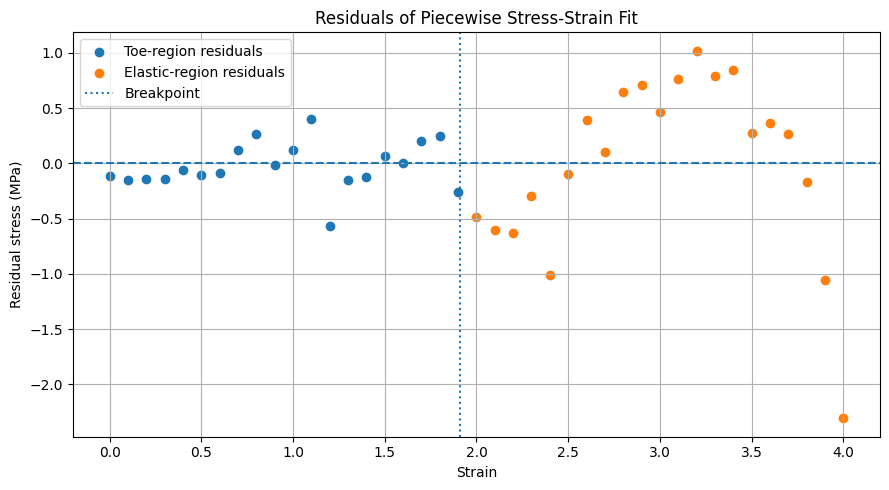

In [133]:
toe_residuals = toe_stress - predicted_toe
elastic_residuals = elastic_stress - predicted_elastic

plt.figure(figsize=(9, 5))

plt.scatter(
    toe_strain, toe_residuals,
    label="Toe-region residuals"
)

plt.scatter(
    elastic_strain, elastic_residuals,
    label="Elastic-region residuals"
)

plt.axhline(0, linestyle="--")

plt.axvline(
    breakpoint,
    linestyle=":",
    label="Breakpoint"
)

plt.xlabel("Strain")
plt.ylabel("Residual stress (MPa)")
plt.title("Residuals of Piecewise Stress-Strain Fit")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Breakpoint strain: 2.700000
Toe-region length: 2.700000
Toe transition stress: 36.445989
Elastic transition stress: 36.385675
Transition stress gap: -0.060314
Toe stiffness at transition: 27.724703
Elastic modulus: 19.284801
Toe R-squared: 0.9983
Elastic R-squared: 0.9931
Overall R-squared: 0.9994
Combined error: 0.601887
Toe MSE: 0.181725
Elastic MSE: 0.420162


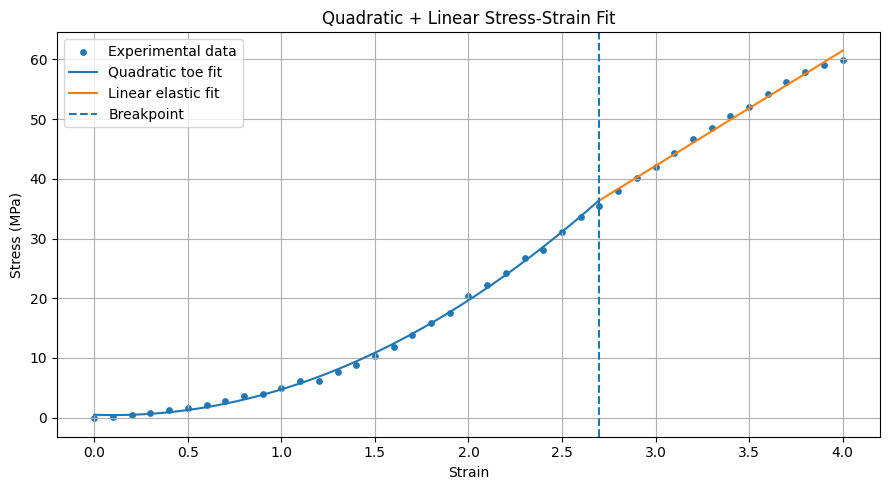

In [134]:
def quadratic(x, a, b, c):
    return a * x**2 + b * x + c

def linear(x, E, d):
    return E * x + d

min_points = 14  #toe region
results = []

# Sort data by strain
order = np.argsort(strain)
strain = np.asarray(strain, dtype=float)[order]
stress = np.asarray(stress, dtype=float)[order]


# Search candidate breakpoints
for i in range(min_points, len(strain) - min_points + 1):

    breakpoint = strain[i]

    toe_x, toe_y = strain[:i], stress[:i]
    elastic_x, elastic_y = strain[i:], stress[i:]

    # Fit quadratic toe region
    a, b, c = np.polyfit(toe_x, toe_y, 2)
    toe_pred = quadratic(toe_x, a, b, c)

    # Fit linear elastic region
    E, d = np.polyfit(elastic_x, elastic_y, 1)
    elastic_pred = linear(elastic_x, E, d)

    # Mean squared errors
    toe_mse = np.mean((toe_y - toe_pred)**2)
    elastic_mse = np.mean((elastic_y - elastic_pred)**2)

    # Combined raw error
    total_mse = toe_mse + elastic_mse

    results.append({
        "breakpoint": breakpoint,
        "index": i,
        "a": a, "b": b, "c": c,
        "E": E, "d": d,
        "toe_mse": toe_mse,
        "elastic_mse": elastic_mse,
        "total_mse": total_mse
    })



results_df = pd.DataFrame(results)

if results_df.empty:
    raise ValueError("No valid breakpoint was found.")

best_result = results_df.loc[
    results_df["total_mse"].idxmin()
]

# Extract the best fit
i = int(best_result["index"])
breakpoint = float(best_result["breakpoint"])

toe_x, toe_y = strain[:i], stress[:i]
elastic_x, elastic_y = strain[i:], stress[i:]

a, b, c = best_result[["a", "b", "c"]]
E, d = best_result[["E", "d"]]

toe_pred = quadratic(toe_x, a, b, c)
elastic_pred = linear(elastic_x, E, d)

# Research parameters
toe_length = breakpoint - strain.min()
toe_transition_stress = quadratic(breakpoint, a, b, c)
elastic_transition_stress = linear(breakpoint, E, d)
toe_stiffness = 2 * a * breakpoint + b
elastic_modulus = E

def r_squared(y, y_pred):
    sse = np.sum((y - y_pred)**2)
    sst = np.sum((y - np.mean(y))**2)
    return 1 - sse / sst if sst > 0 else np.nan

toe_r2 = r_squared(toe_y, toe_pred)
elastic_r2 = r_squared(elastic_y, elastic_pred)

all_pred = np.concatenate([toe_pred, elastic_pred])
overall_r2 = r_squared(stress, all_pred)

# Summary for this test
print(f"Breakpoint strain: {breakpoint:.6f}")
print(f"Toe-region length: {toe_length:.6f}")
print(f"Toe transition stress: {toe_transition_stress:.6f}")
print(f"Elastic transition stress: {elastic_transition_stress:.6f}")
print(f"Transition stress gap: "
      f"{elastic_transition_stress - toe_transition_stress:.6f}")
print(f"Toe stiffness at transition: {toe_stiffness:.6f}")
print(f"Elastic modulus: {elastic_modulus:.6f}")
print(f"Toe R-squared: {toe_r2:.4f}")
print(f"Elastic R-squared: {elastic_r2:.4f}")
print(f"Overall R-squared: {overall_r2:.4f}")
print(f"Combined error: {best_result['total_mse']:.6f}")

toe_mse = float(best_result["toe_mse"])
elastic_mse = float(best_result["elastic_mse"])

print(f"Toe MSE: {toe_mse:.6f}")
print(f"Elastic MSE: {elastic_mse:.6f}")

# Plot fitted curve
plt.figure(figsize=(9, 5))
plt.scatter(strain, stress, s=15, label="Experimental data")

x_toe = np.linspace(toe_x.min(), breakpoint, 150)
x_elastic = np.linspace(breakpoint, elastic_x.max(), 150)

plt.plot(x_toe, quadratic(x_toe, a, b, c),
         label="Quadratic toe fit")
plt.plot(x_elastic, linear(x_elastic, E, d),
         label="Linear elastic fit")
plt.axvline(breakpoint, linestyle="--", label="Breakpoint")

plt.xlabel("Strain")
plt.ylabel("Stress (MPa)")
plt.title("Quadratic + Linear Stress-Strain Fit")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


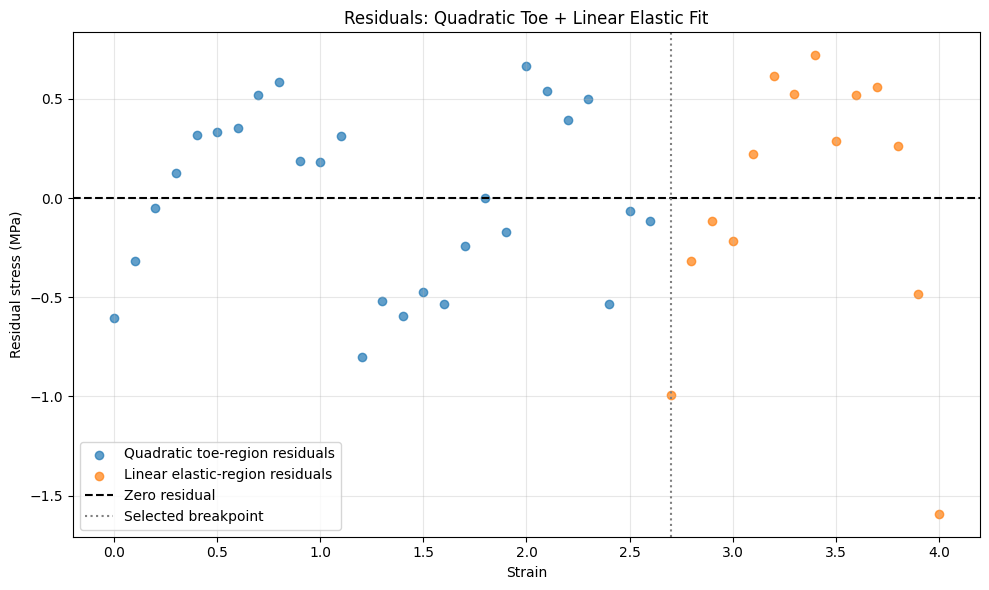

In [135]:
# Residual plot: Quadratic + Linear Fit
# ------------------------------------------

# Calculate residuals for the quadratic model
quad_toe_residuals = toe_y - toe_pred

# Calculate residuals for the linear elastic model
quad_elastic_residuals = elastic_y - elastic_pred

# Create residual graph
plt.figure(figsize=(10, 6))

plt.scatter(
    toe_x,
    quad_toe_residuals,
    label="Quadratic toe-region residuals",
    alpha=0.7
)

plt.scatter(
    elastic_x,
    quad_elastic_residuals,
    label="Linear elastic-region residuals",
    alpha=0.7
)

# Reference line at zero
plt.axhline(
    y=0,
    linestyle="--",
    color="black",
    label="Zero residual"
)

# Mark the selected breakpoint
plt.axvline(
    x=breakpoint,
    linestyle=":",
    color="grey",
    label="Selected breakpoint"
)

plt.xlabel("Strain")
plt.ylabel("Residual stress (MPa)")
plt.title("Residuals: Quadratic Toe + Linear Elastic Fit")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
